# 12 — Perceptroni dhe ura drejt rrjetave nervore

        **Pyetja udhëheqëse:** Sa larg mund të shkojmë me një ndarës linear që mëson nga gabimet?

        Ky notebook është ndërtuar si një mësim i plotë kompjuterik. Rruga kryesore ndjek:
        **problem konkret → model matematikor → zbatim nga parimet e para → bibliotekë profesionale → krahasim → interpretim**.

        ## Objektivat
        - Të implementohet perceptroni nga zero.
- Të kuptohet rregulli i përditësimit dhe konvergjenca.
- Të analizohet dështimi në të dhëna jo të ndashme linearisht.
- Të kuptohet ura konceptuale drejt rrjetave nervore.

        > **Rruga bazë për orën mësimore (45–60 min)** shënohet me seksionet **CORE**.  
        > Seksionet **EXTENDED** dhe **PLAYGROUND** janë për thellim dhe punë të pavarur.

## Pse kjo temë është e nevojshme?

Perceptroni është modeli më i thjeshtë që kombinon një shumë të peshuar, një rregull vendimi dhe një rregull mësimi nga gabimi. Pikërisht për këtë arsye është fundi i natyrshëm i kursit: përmbledh klasifikimin linear dhe hap derën drejt rrjetave nervore pa kaluar ende te backpropagation.

Do të kuptojmë kur perceptroni konvergon, pse dështimi në të dhëna jo të ndashme është strukturor dhe pse XOR motivon nevojën për përfaqësime jolineare dhe shtresa të fshehta.

### Si duhet lexuar ky notebook

Për çdo bllok kodi do të shpjegojmë **pse** kryhet ai hap, çfarë pyetjeje i përgjigjet dhe çfarë duhet të kontrollojmë në dalje. Kodi nuk trajtohet si recetë: çdo grafik dhe çdo metrikë duhet të rikthehet te hipoteza matematikore dhe te interpretimi fizik. Kur një rezultat nuk sillet siç presim, pyetja e parë nuk është “si ta rrisim score-in?”, por “cilën hipotezë të modelit ose të të dhënave po shkelim?”.

### Para se të ekzekutojmë: Mjedisi llogaritës dhe riprodhueshmëria

Ngarkojmë bibliotekat që do të përdoren dhe fiksojmë `RANDOM_STATE = 42`. Ky seed nuk e bën problemin determinist në kuptimin fizik; ai thjesht na lejon të përsërisim të njëjtin eksperiment llogaritës dhe të diskutojmë metodën pa u hutuar nga ndryshime të rastësishme të mostrës.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [1]:
# Qëllimi i këtij blloku: Mjedisi llogaritës dhe riprodhueshmëria.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import numpy as np
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import pandas as pd
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import matplotlib.pyplot as plt
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from pathlib import Path
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import time

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("12 — Perceptroni dhe ura drejt rrjetave nervore")
print("Seed:", RANDOM_STATE)

12 — Perceptroni dhe ura drejt rrjetave nervore
Seed: 42


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 1. Neuroni artificial si ndarës linear — CORE

Perceptroni përdor
$$
z=\mathbf w^T\mathbf x+b,
$$
dhe vendimin
$$
\hat y=\mathrm{sign}(z).
$$
Nëse një mostër $(x_i,y_i)$ klasifikohet gabim, përditësojmë
$$
\mathbf w\leftarrow\mathbf w+\eta y_i\mathbf x_i,\qquad
b\leftarrow b+\eta y_i.
$$

### Para se të ekzekutojmë: Klasat linearisht të ndashme

Fillojmë me një rast ku teorema e konvergjencës së perceptronit ka kuptim. Nëse klasat ndahen me një hiperplan, algoritmi duhet të gjejë një zgjidhje pas një numri të fundëm gabimesh.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

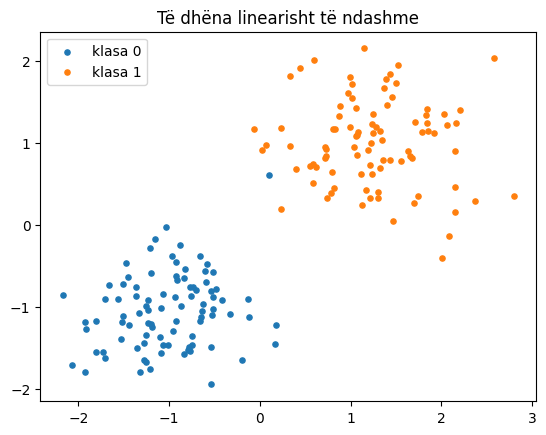

In [2]:
# Qëllimi i këtij blloku: Klasat linearisht të ndashme.
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
X0=rng.normal([-1,-1],[0.55,0.55],size=(90,2))
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
X1=rng.normal([1.2,1.0],[0.55,0.55],size=(90,2))
X=np.vstack([X0,X1]); y=np.r_[np.zeros(len(X0)),np.ones(len(X1))]
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.scatter(X0[:,0],X0[:,1],s=14,label="klasa 0")
ax.scatter(X1[:,0],X1[:,1],s=14,label="klasa 1")
ax.legend(); ax.set_title("Të dhëna linearisht të ndashme")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 2. Zbatim nga parimet e para — CORE

### Para se të ekzekutojmë: Rregulli i mësimit nga gabimi

Implementimi manual është i shkurtër, por çdo hap është konceptualisht i rëndësishëm: transformojmë etiketat në $\pm1$, kontrollojmë margjinën e shenjës dhe ndryshojmë peshat vetëm kur mostra nuk klasifikohet saktë.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [3]:
# Qëllimi i këtij blloku: Rregulli i mësimit nga gabimi.
def train_perceptron(X,y,eta=1.0,max_epochs=100,seed=42):
    yt=np.where(y>0,1.0,-1.0)
    w=np.zeros(X.shape[1]); b=0.0
    rng_local=np.random.default_rng(seed)
    mistakes=[]
    # Përsërisim procedurën për të studiuar konvergjencën ose ndjeshmërinë ndaj parametrave.
    for _ in range(max_epochs):
        m=0
        for i in rng_local.permutation(len(X)):
            if yt[i]*(X[i]@w+b)<=0:
                w+=eta*yt[i]*X[i]
                b+=eta*yt[i]
                m+=1
        mistakes.append(m)
        if m==0: break
    return w,b,np.array(mistakes)

w,b,mist=train_perceptron(X,y)
w,b,len(mist)

(array([3.38855738, 2.15126208]), np.float64(-2.0), 100)

### Perceptroni kanonik nga `src/`

### Para se të ekzekutojmë: Versioni kanonik i perceptronit

Pas implementimit didaktik përdorim klasën e `src/`. Kjo siguron një version të ripërdorshëm pa humbur transparencën matematikore të hapit të mëparshëm.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [4]:
# Qëllimi i këtij blloku: Versioni kanonik i perceptronit.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import sys
# Kërkojmë automatikisht rrënjën e repository-t, në mënyrë që notebook-u të funksionojë nga dosje të ndryshme.
ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src").is_dir():
        sys.path.insert(0, str(candidate))
        break
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from src.perceptron.perceptron import PerceptronFromScratch
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
per_src = PerceptronFromScratch(max_epochs=100, seed=RANDOM_STATE).fit(X, y)
print("Epokat:", per_src.n_iter_, "gabimet e fundit:", per_src.mistakes_per_epoch_[-1])

Epokat: 100 gabimet e fundit: 2


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 3. Kufiri dhe konvergjenca — CORE

### Para se të ekzekutojmë: Kufiri dhe historia e gabimeve

Vizatojmë njëkohësisht hiperplanin final dhe numrin e gabimeve për epokë. Konvergjenca nuk është thjesht ulje e një loss-i të vazhdueshëm; te perceptroni ajo shfaqet si epokë pa gabime.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

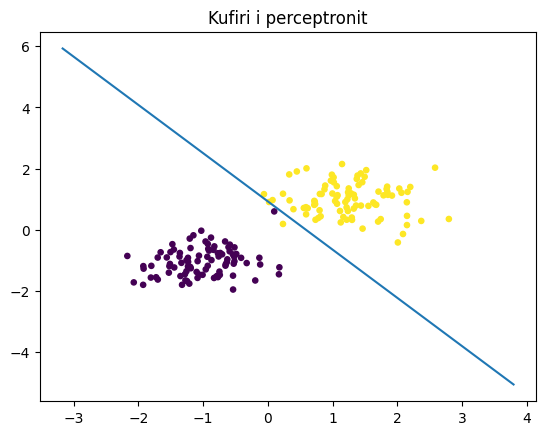

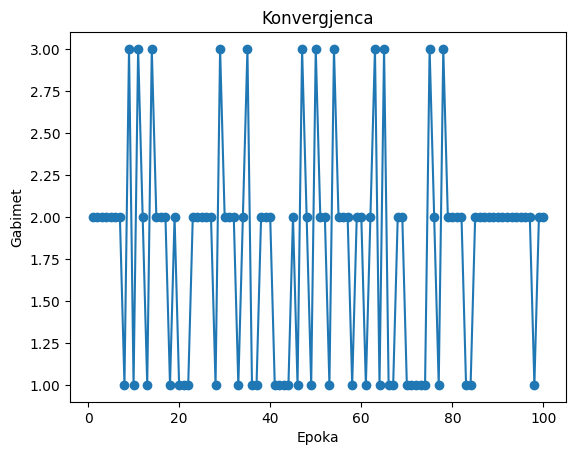

In [5]:
# Qëllimi i këtij blloku: Kufiri dhe historia e gabimeve.
xx=np.linspace(X[:,0].min()-1,X[:,0].max()+1,200)
yy=-(w[0]*xx+b)/w[1]
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.scatter(X[:,0],X[:,1],c=y,s=14)
ax.plot(xx,yy)
ax.set_title("Kufiri i perceptronit")
plt.show()

# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.plot(np.arange(1,len(mist)+1),mist,marker="o")
ax.set_xlabel("Epoka"); ax.set_ylabel("Gabimet")
ax.set_title("Konvergjenca")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 4. Krahasim me sklearn — CORE

### Para se të ekzekutojmë: Krahasimi me implementimin profesional

Koeficientët nuk kanë pse të jenë identikë sepse perceptroni mund të konvergojë në disa kufij ndarës. Ajo që duhet të krahasojmë është sjellja e klasifikimit dhe konsistenca e parimit.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [6]:
# Qëllimi i këtij blloku: Krahasimi me implementimin profesional.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.linear_model import Perceptron
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
p=Perceptron(random_state=RANDOM_STATE,max_iter=1000,tol=1e-4).fit(X,y)
print("manual:",w,b)
print("sklearn:",p.coef_[0],p.intercept_[0])

manual: [3.38855738 2.15126208] -2.0
sklearn: [2.39294273 2.10179402] 0.0


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 5. Të dhëna me zhurmë dhe jo të ndashme — CORE

### Para se të ekzekutojmë: Kur hipoteza e ndarjes lineare prishet

Përmbysim disa etiketa që të krijojmë konflikt të brendshëm. Në këtë rast algoritmi vazhdon të bëjë gabime sepse nuk ekziston asnjë hiperplan që i kënaq të gjitha mostrat.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

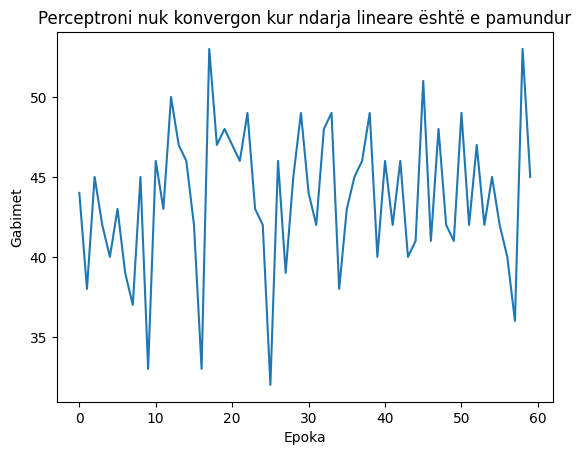

In [7]:
# Qëllimi i këtij blloku: Kur hipoteza e ndarjes lineare prishet.
Xn=X.copy()
yn=y.copy()
flip=rng.choice(len(yn),size=22,replace=False)
yn[flip]=1-yn[flip]
_,_,mist_n=train_perceptron(Xn,yn,max_epochs=60)
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.plot(mist_n)
ax.set_xlabel("Epoka"); ax.set_ylabel("Gabimet")
ax.set_title("Perceptroni nuk konvergon kur ndarja lineare është e pamundur")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 6. XOR: kufiri themelor — CORE

### Para se të ekzekutojmë: XOR si kundërshembull strukturor

XOR është shembulli klasik ku të katër pikat janë krejt të pastra, por jo linearisht të ndashme. Dështimi nuk vjen nga zhurma apo optimizimi: klasa e modelit është e pamjaftueshme.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

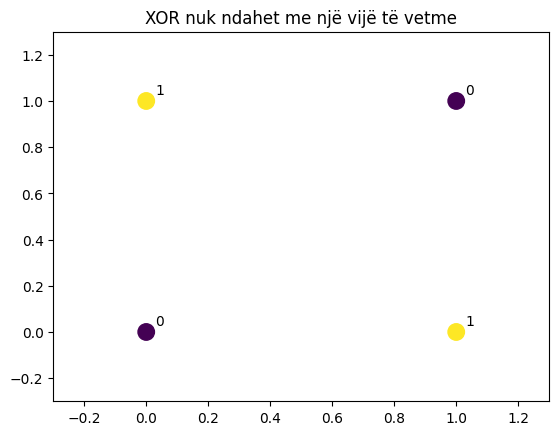

In [8]:
# Qëllimi i këtij blloku: XOR si kundërshembull strukturor.
Xxor=np.array([[0,0],[0,1],[1,0],[1,1]],float)
yxor=np.array([0,1,1,0])
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.scatter(Xxor[:,0],Xxor[:,1],c=yxor,s=140)
for i,(a,bx) in enumerate(Xxor):
    ax.text(a+0.03,bx+0.03,str(yxor[i]))
ax.set_xlim(-0.3,1.3); ax.set_ylim(-0.3,1.3)
ax.set_title("XOR nuk ndahet me një vijë të vetme")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

**Interpretim.** Dështimi në XOR nuk është problem i algoritmit të trajnimit; është kufizim i klasës së modeleve lineare. Kjo motivon shtresa të fshehta dhe transformime jolineare.

Në një analizë reale ky interpretim duhet të shoqërohet me kontroll të njësive, madhësive karakteristike dhe hipotezave që lejojnë kalimin nga një tregues numerik te një përfundim fizik.

---
## Deri këtu: materiali bazë për orën mësimore

Në një seancë rreth 60 minuta, zakonisht ndalemi këtu. Seksionet që vijojnë janë për thellim,
ushtrime të pavarura dhe eksperimentim.

# 7. Ura drejt rrjetave nervore — EXTENDED

Një rrjet me shumë shtresa kombinon transformime lineare me funksione aktivizimi jolineare:
$$
h=\phi(Wx+b).
$$
Shtresat e fshehta mund të ndërtojnë përfaqësime ku probleme si XOR bëhen linearisht të ndashme.
Trajnimi i rrjeteve moderne përdor **prapapërhapjen (backpropagation)** dhe variante të zbritjes
stokastike të gradientit. Këtu ndalemi: këto tema i përkasin trajtimit të mëvonshëm në nivel Master.

### Para se të ekzekutojmë: Një përfaqësim i ri ndryshon problemin

Ndërtojmë me dorë një veçori jolineare që e bën XOR të thjeshtë. Ky eksperiment tregon idenë themelore pas shtresave të fshehta: modeli mëson ose ndërton një përfaqësim ku ndarja bëhet më e lehtë.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

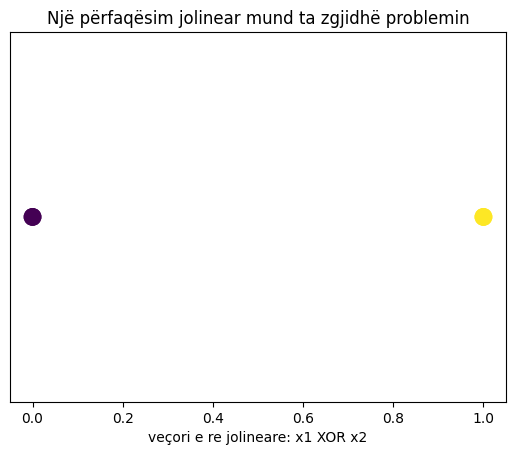

In [9]:
# Qëllimi i këtij blloku: Një përfaqësim i ri ndryshon problemin.
# Një transformim i thjeshtë i projektuar me dorë që e bën XOR të dallueshëm
z = (Xxor[:,0] != Xxor[:,1]).astype(float)
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.scatter(z, np.zeros_like(z), c=yxor, s=140)
ax.set_xlabel("veçori e re jolineare: x1 XOR x2")
ax.set_yticks([])
ax.set_title("Një përfaqësim jolinear mund ta zgjidhë problemin")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 8. Aplikim fizik: ndarje regjimesh — EXTENDED

Në një hapësirë veçorish të ndërtuar nga amplituda dhe frekuenca, perceptroni mund të funksionojë mirë vetëm nëse regjimet ndahen afërsisht me një hiperplan. Ky kusht duhet kontrolluar, jo supozuar.

# Ushtrime — PLAYGROUND

        ## A. Ushtrime të shkurtra
        1. Ndryshoni learning rate dhe numëroni epokat deri në konvergjencë.
2. Zhvendosni klasat gradualisht derisa të mbivendosen.
3. Krahasoni perceptronin me regresionin logjistik.
4. Shpjegoni pse XOR kërkon jolinearitet.

        ## B. Ushtrim i plotë
        Ndërtoni një dataset me tre veçori ku klasat janë të ndashme dhe verifikoni konvergjencën e perceptronit; më pas shtoni zhurmë etikete dhe analizoni gabimet për epokë.

        ## C. Playground
        Ndryshoni learning rate, seed, mbivendosjen dhe numrin e gabimeve në etiketa.

In [10]:
# TODO / PLAYGROUND
# Ndryshoni parametrat, shtoni grafikë ose krahasoni modele të tjera.

## Përmbledhje konceptuale e kapitullit

Notebook-u **Perceptroni dhe ura drejt rrjetave nervore** duhet të lihet me një ide të qartë: algoritmi është vetëm një hallkë e arsyetimit. Para tij kemi zgjedhjen e përfaqësimit dhe hipotezat mbi të dhënat; pas tij kemi validimin, diagnostikën dhe interpretimin. Nëse një student mund të ekzekutojë të gjitha qelizat por nuk mund të shpjegojë pse secila prej tyre është e nevojshme, atëherë puna llogaritëse nuk është përfunduar ende.

Për studim të mëtejshëm, rikthehuni te shënimet e leksionit për derivimet e plota dhe përdoreni këtë notebook si laborator ku këto ide testohen numerikisht.

### Zgjidhje orientuese për instruktorin
- Për të dhëna linearisht të ndashme, perceptroni konvergon në një numër të fundëm përditësimesh.
- Kur klasat mbivendosen ose etiketat janë të gabuara, numri i gabimeve nuk shkon domosdoshmërisht në zero.
- XOR nuk zgjidhet nga një hiperplan; kërkohet transformim jolinear ose shtresë e fshehtë.